In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, 
                             confusion_matrix, roc_auc_score, roc_curve, 
                             precision_recall_curve, auc, RocCurveDisplay, PrecisionRecallDisplay)

# 1. Carregando os Dados
X_train = pd.read_csv('../data/processed/X_train_class.csv')
X_test = pd.read_csv('../data/processed/X_test_class.csv')
y_train = pd.read_csv('../data/processed/y_train_class.csv').squeeze()
y_test = pd.read_csv('../data/processed/y_test_class.csv').squeeze()
X_test_limpo = pd.read_csv('../data/processed/data_limpo_class.csv')

SEED = 42

In [2]:
# 1. Árvore de Decisão Otimizada
arvore = DecisionTreeClassifier(
    criterion='entropy',
    max_depth=2,
    min_samples_leaf=1,
    min_samples_split=2,
    random_state=SEED
)
arvore.fit(X_train, y_train)

# 2. Random Forest Otimizado
floresta = RandomForestClassifier(
    max_depth=3, 
    min_samples_leaf=1, 
    n_estimators=75,
    random_state=SEED,
    n_jobs=-1  # O Random Forest é o único que aceita n_jobs para paralelismo nativo
)
floresta.fit(X_train, y_train)

# 3. Gradient Boosting Otimizado
boosting = GradientBoostingClassifier(
    learning_rate=0.01, 
    max_depth=5, 
    n_estimators=200,
    random_state=SEED
)
boosting.fit(X_train, y_train)

,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.01
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",200
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (i

In [3]:
class Rule:
    def __init__(self, rule_id, condition_fn, target_class, rule_type, salience=1):
        self.rule_id = rule_id
        self.condition_fn = condition_fn  # Função lambda que avalia o fato (linha)
        self.target_class = target_class
        self.rule_type = rule_type        # Relação, Recomendação, Diretriz, Estratégia, Heurística
        self.salience = salience          # Prioridade para desempate

class ExpertSystemClassifier:
    def __init__(self, default_class=0):
        self.rules = []
        self.default_class = default_class

    def add_rule(self, rule: Rule):
        self.rules.append(rule)
        # Ordena regras por prioridade (salience) decrescente
        self.rules.sort(key=lambda r: r.salience, reverse=True)

    def predict_instance(self, row):
        """Aplica Forward Chaining na instância (linha do dataset)."""
        for rule in self.rules:
            if rule.condition_fn(row):
                return rule.target_class
        return self.default_class

    def predict(self, X):
        """Realiza a inferência para todo o dataset e meça a eficiência."""
        predictions = []
        for idx, row in X.iterrows():
            predictions.append(self.predict_instance(row))
        return np.array(predictions)

In [4]:
expert_model = ExpertSystemClassifier(default_class=0)

# Adicionando regras (Ajuste os nomes das colunas e os limites conforme seu dataset de treino)
expert_model.add_rule(Rule(
    rule_id="R1",
    condition_fn=lambda r: r['prior_gpa'] <= 3,
    target_class=0,
    rule_type="Relação",
    salience=1
))

expert_model.add_rule(Rule(
    rule_id="R2",
    condition_fn=lambda r: r['sleep_midpoint_minutes'] > 540,
    target_class=0,
    rule_type="Relação",
    salience=1
))

expert_model.add_rule(Rule(
    rule_id="R3",
    condition_fn=lambda r: 7.5 >= r['avg_sleep_hours'] >= 6.5 and r['first_generation'] == 1,
    target_class=0,
    rule_type="Relação",
    salience=2
))

expert_model.add_rule(Rule(
    rule_id="R4",
    condition_fn=lambda r: r['underrepresented'] == 1 and r['sleep_midpoint_minutes'] > 520,
    target_class=0,
    rule_type="Relação",
    salience=2
))

expert_model.add_rule(Rule(
    rule_id="R5",
    condition_fn=lambda r: (r['sleep_midpoint_minutes'] <= 300 or 310 >= r['sleep_midpoint_minutes'] <= 340) and r['first_generation'] == 1,
    target_class=0,
    rule_type="Relação",
    salience=3
))

expert_model.add_rule(Rule(
    rule_id="R6",
    condition_fn=lambda r: r['prior_gpa'] > 3.80 and r['sleep_midpoint_minutes'] <= 531.80,
    target_class=1,
    rule_type="Relação",
    salience=2
))

expert_model.add_rule(Rule(
    rule_id="R7",
    condition_fn=lambda r: r['prior_gpa'] > 3.16 and r['avg_sleep_hours'] >= 5.97,
    target_class=0,
    rule_type="Relação",
    salience=2
))

expert_model.add_rule(Rule(
    rule_id="R8",
    condition_fn=lambda r: r['prior_gpa'] <= 3.66 and r['avg_sleep_hours'] > 4.51,
    target_class=0,
    rule_type="Relação",
    salience=2
))

In [5]:
from sklearn.model_selection import train_test_split

# 1. Carregue o dataset limpo inteiro (da atividade anterior)
# Se a sua coluna alvo não se chamar 'target', substitua pelo nome correto abaixo.
df_limpo = pd.read_csv('../data/processed/data_limpo_class.csv')
X_limpo = df_limpo.drop(columns=['gpa_category_encoded']) 
y_limpo = df_limpo['gpa_category_encoded']

# 2. Refazemos o split usando a MESMA semente dos outros modelos (ex: 42 ou sua SEED)
# Isso garante que as 126 linhas sorteadas para teste sejam exatamente as mesmas.
_, X_test_limpo, _, _ = train_test_split(
    X_limpo, 
    y_limpo, 
    test_size=0.2, 
    random_state=42, # IMPORTANTE: Coloque aqui o mesmo valor da sua SEED!
    stratify=y_limpo
)

# 3. Agora o Sistema Especialista faz a previsão no conjunto do tamanho certo
especialista = expert_model.predict(X_test_limpo)

print(f"Tamanho do y_test: {len(y_test)}")
print(f"Novo tamanho das previsões do especialista: {len(especialista)}")

Tamanho do y_test: 126
Novo tamanho das previsões do especialista: 126


In [6]:
from sklearn.metrics import precision_recall_curve, auc

def calcular_metricas(nome, y_true, y_pred, y_probs=None):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    
    # Se o modelo gera probabilidades (Árvores e Ensembles), calcula AUCs. 
    # Se não gera (Sistema Especialista), retorna 'N/A'
    if y_probs is not None:
        roc = roc_auc_score(y_true, y_probs)
        precision_curve, recall_curve, _ = precision_recall_curve(y_true, y_probs)
        pr_auc = auc(recall_curve, precision_curve)
    else:
        roc = 'N/A'
        pr_auc = 'N/A'
        
    return {
        'Modelo': nome, 
        'Acurácia': round(acc, 4), 
        'Precision': round(prec, 4), 
        'Recall': round(rec, 4), 
        'F1-Score': round(f1, 4), 
        'ROC-AUC': round(roc, 4) if roc != 'N/A' else roc,
        'PR-AUC': round(pr_auc, 4) if pr_auc != 'N/A' else pr_auc
    }

In [7]:
# =========================================================
# 2. CALCULANDO OS RESULTADOS DE TODOS OS MODELOS
# =========================================================
# O Especialista não tem probabilidade (y_probs=None)
res_especialista = calcular_metricas('Sistema Especialista', y_test, especialista, None)

res_arvore = calcular_metricas('Árvore de Decisão', y_test, arvore.predict(X_test), arvore.predict_proba(X_test)[:, 1])
res_floresta = calcular_metricas('Random Forest', y_test, floresta.predict(X_test), floresta.predict_proba(X_test)[:, 1])
res_boosting = calcular_metricas('Gradient Boosting', y_test, boosting.predict(X_test), boosting.predict_proba(X_test)[:, 1])

In [8]:
# =========================================================
# 3. EXIBINDO A TABELA FINAL
# =========================================================
df_metricas = pd.DataFrame([res_especialista, res_arvore, res_floresta, res_boosting])
print("=== TABELA DE MÉTRICAS (CONJUNTO DE TESTE) ===")
display(df_metricas)

=== TABELA DE MÉTRICAS (CONJUNTO DE TESTE) ===


,Modelo,Acurácia,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Sistema Especialista,0.6508,1.0000,0.3125,0.4762,N/A,N/A
1,Árvore de Decisão,0.7540,0.8113,0.6719,0.7350,0.8267,0.8692
2,Random Forest,0.7143,0.7500,0.6562,0.7000,0.8275,0.8357
3,Gradient Boosting,0.7063,0.7288,0.6719,0.6992,0.7826,0.8158


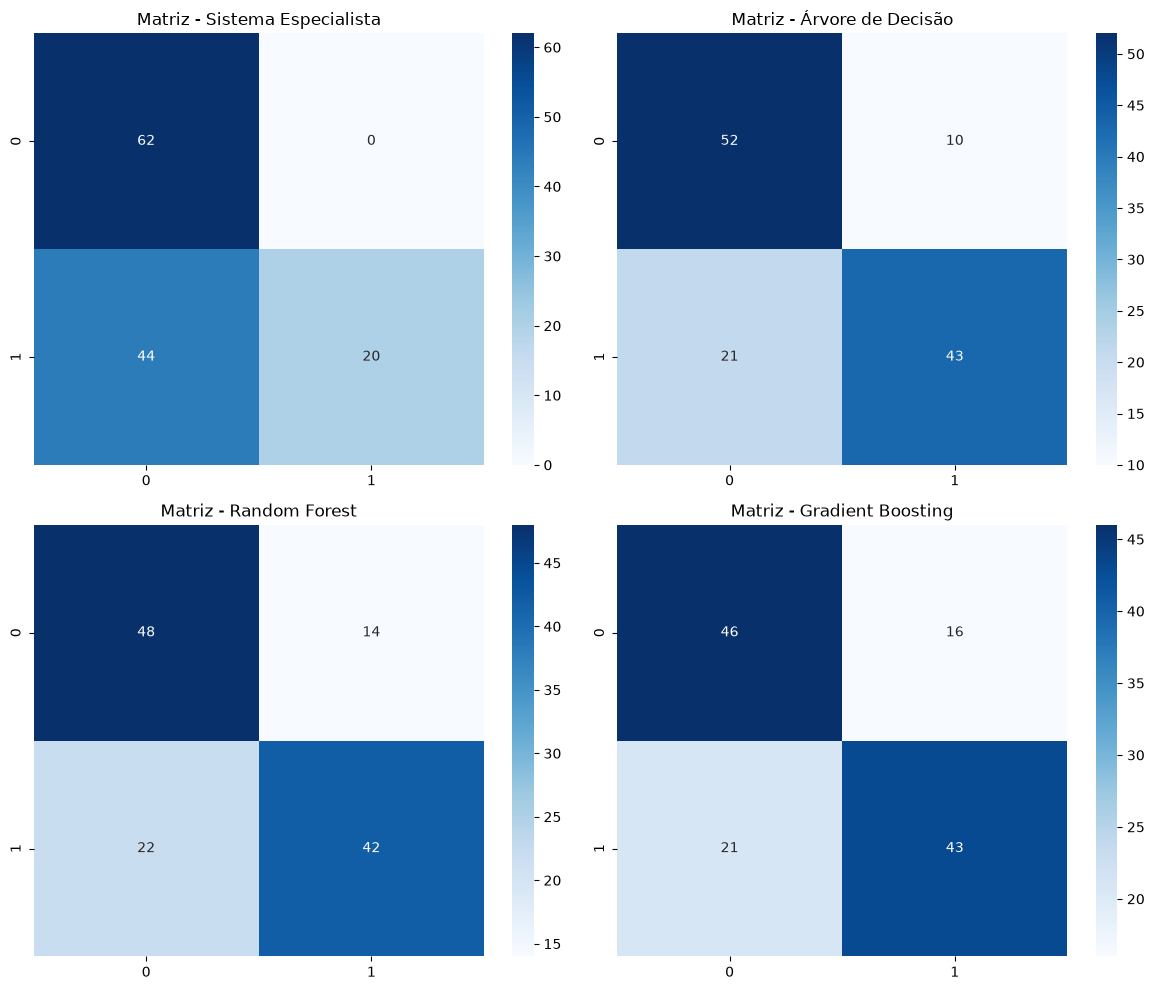

In [9]:
# =========================================================
# 4. PLOTANDO AS 4 MATRIZES DE CONFUSÃO (GRADE 2x2)
# =========================================================
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

sns.heatmap(confusion_matrix(y_test, especialista), annot=True, fmt='d', cmap='Blues', ax=axes[0, 0])
axes[0, 0].set_title('Matriz - Sistema Especialista')

sns.heatmap(confusion_matrix(y_test, arvore.predict(X_test)), annot=True, fmt='d', cmap='Blues', ax=axes[0, 1])
axes[0, 1].set_title('Matriz - Árvore de Decisão')

sns.heatmap(confusion_matrix(y_test, floresta.predict(X_test)), annot=True, fmt='d', cmap='Blues', ax=axes[1, 0])
axes[1, 0].set_title('Matriz - Random Forest')

sns.heatmap(confusion_matrix(y_test, boosting.predict(X_test)), annot=True, fmt='d', cmap='Blues', ax=axes[1, 1])
axes[1, 1].set_title('Matriz - Gradient Boosting')

plt.tight_layout()
os.makedirs('../reports/figures', exist_ok=True)
plt.savefig('../reports/figures/matrizes_confusao.png', bbox_inches='tight', dpi=300)

plt.show()

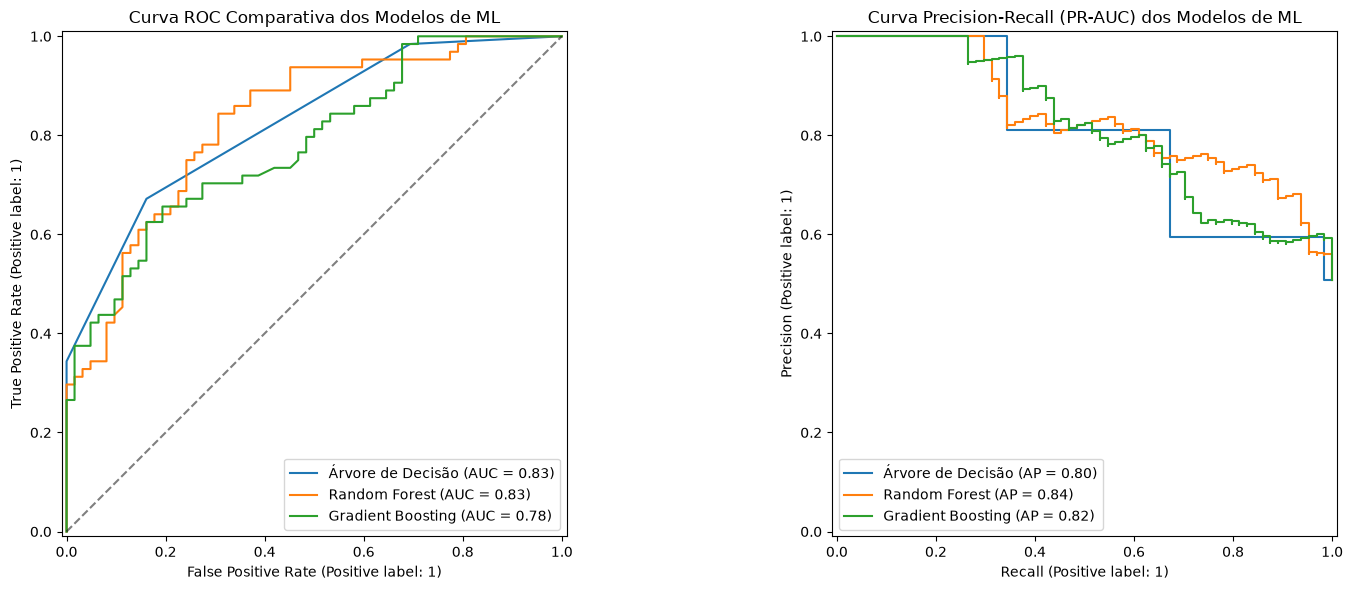

In [10]:
# =========================================================
# 5. PLOTANDO A CURVA ROC E A CURVA PR-AUC LADO A LADO
# =========================================================
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico 1: Curva ROC
RocCurveDisplay.from_estimator(arvore, X_test, y_test, ax=ax_roc, name='Árvore de Decisão')
RocCurveDisplay.from_estimator(floresta, X_test, y_test, ax=ax_roc, name='Random Forest')
RocCurveDisplay.from_estimator(boosting, X_test, y_test, ax=ax_roc, name='Gradient Boosting')
ax_roc.plot([0, 1], [0, 1], 'k--', alpha=0.5)
ax_roc.set_title('Curva ROC Comparativa dos Modelos de ML')

# Gráfico 2: Curva PR-AUC
PrecisionRecallDisplay.from_estimator(arvore, X_test, y_test, ax=ax_pr, name='Árvore de Decisão')
PrecisionRecallDisplay.from_estimator(floresta, X_test, y_test, ax=ax_pr, name='Random Forest')
PrecisionRecallDisplay.from_estimator(boosting, X_test, y_test, ax=ax_pr, name='Gradient Boosting')
ax_pr.set_title('Curva Precision-Recall (PR-AUC) dos Modelos de ML')

plt.tight_layout()
os.makedirs('../reports/figures', exist_ok=True)
plt.savefig('../reports/figures/Curvas ROC e PR-AUC.png', bbox_inches='tight', dpi=300)

plt.show()